# XGBoost PM2.5 — full network, five-arm ablation, continuous surfaces

Runs on the **84-sensor network** (not the 18-sensor pilot) with the station split shared with the
CNN-LSTM branch (54 train / 13 calibration / 16 test), and renders the surfaces as a **continuous
gradient** rather than AQI tiers.

Works locally (from `XGBoost/`) and on Kaggle. Training is skipped automatically when
`outputs/ablation_results.csv` already holds all five arms.


In [1]:
# ---- 0. where are we? (Kaggle copies out of the read-only mount; locally we are already in the folder)
import glob, os, shutil, subprocess

ON_KAGGLE = os.path.exists('/kaggle')
if ON_KAGGLE:
    hits = glob.glob('/kaggle/input/**/run_pipeline.py', recursive=True)
    if not hits:
        raise SystemExit('dataset not attached: right-hand panel -> Add Input -> your dataset')
    shutil.copytree(os.path.dirname(hits[0]), '/kaggle/working/XGBoost', dirs_exist_ok=True)
    os.chdir('/kaggle/working/XGBoost')
    if subprocess.run(['python', '-c', 'import skopt'], capture_output=True).returncode:
        subprocess.run(['pip', 'install', '-q', 'scikit-optimize', 'shap'], check=True)

os.environ['XGB_DATASET'] = 'full'      # the 84-sensor network
os.environ['XGB_FOLDS']   = 'shared'    # 54 / 13 / 16, comparable to the CNN-LSTM run

import data
print('working in :', os.getcwd())
print('folds      :', os.path.basename(data.FOLD_JSON))
print('master     :', os.path.basename(data.MASTER_CSV))
assert data.FOLD_JSON.endswith('fold_partitions_shared.json'), 'wrong split -- XGB_FOLDS=shared failed'
assert os.path.exists(data.MASTER_CSV), 'Master_DL_Ready_full.csv missing: run ingest_sources.py'

working in : C:\Users\delac\Downloads\thesis_model\XGBoost
folds      : fold_partitions_shared.json
master     : Master_DL_Ready_full.csv


## 1. Data and features

`preprocessing.prep` runs on import: it merges the 500 m morphology grid onto the sensor table, builds
gap-aware hourly lags (`pm25_lag_1..4`, 24 h and 72 h rolling means/stds) and the cyclical time terms.
The 10 m raster is the *source* of the morphology; the model never sees a 10 m pixel.

In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from preprocessing import prep
from preprocessing import spatial_cv
from training.ablation import ARM_FEATURES, ARM_LABELS

df_clean = prep.df_clean
MAPPING = data.SENSOR_MAP_CSV
print('rows %s | cells %d | stations %d | features %d'
      % (f'{len(df_clean):,}', df_clean['Grid_ID'].nunique(),
         df_clean['Location'].nunique(), len(prep.features)))
print('period %s .. %s' % (df_clean['DateTime'].min().date(), df_clean['DateTime'].max().date()))

Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
rows 1,479,013 | cells 83 | stations 84 | features 24
period 2021-07-11 .. 2026-10-15


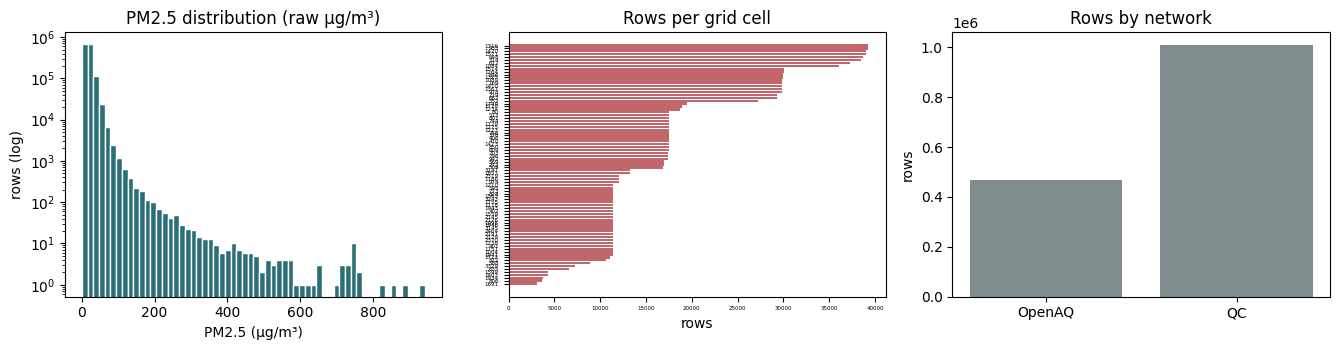

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))

axes[0].hist(df_clean['Value'], bins=60, color='#2a6f77', edgecolor='white')
axes[0].set_yscale('log')
axes[0].set_title('PM2.5 distribution (raw µg/m³)')
axes[0].set_xlabel('PM2.5 (µg/m³)'); axes[0].set_ylabel('rows (log)')

per_cell = df_clean.groupby('Grid_ID').size().sort_values()
axes[1].barh(per_cell.index.astype(str), per_cell.values, color='#c1666b')
axes[1].set_title('Rows per grid cell'); axes[1].set_xlabel('rows')
axes[1].tick_params(labelsize=4)

by_src = df_clean.groupby('source').size() if 'source' in df_clean.columns else None
if by_src is not None:
    axes[2].bar(by_src.index.astype(str), by_src.values, color='#7f8c8d')
    axes[2].set_title('Rows by network'); axes[2].set_ylabel('rows')
plt.tight_layout(); plt.show()

## 1b. EDA findings and the cleaning policy

`eda/eda_results/EDA_Report.md` audits the raw network and makes four recommendations. What each one
means for THIS model, measured rather than assumed:

| EDA finding | Rows affected | Applied here | Measured effect |
|---|---|---|---|
| **Sensor-floor readings** (`<= 0.5 ug/m3`) | 5,292 (0.36%) | **dropped**, before the lags | keeps a 0.0 from becoming next hour's `pm25_lag_1`; model change ~0.3% |
| **New Year's Eve fireworks** (300-529 ug/m3, Dec 31 21:00 - Jan 1 06:00) | 1,389 (0.09%) | **opt-in** (`XGB_CLEAN_NYE=on`) | training on masked data changes the model by ~0.3%, but the *reported* RMSE falls 1.9% and **R2 falls 0.010** purely because 363 extreme rows leave the test set |
| **Staggered QC deployment cohorts** (8 -> 20 -> 40 sensors, 2021-2024) | -- | **not applied as a filter** | the lag now requires >= 2 contributing stations instead of thinning the years |
| **Raw wide-format quirks** (`QC Data/`) | -- | not applicable | this pipeline reads the long-format `QC Data Converted/`, not the wide files |

Two conclusions worth keeping:

1. **NYE masking is deliberately OFF by default.** It lowers RMSE by deleting the hardest rows, which is
   metric cherry-picking unless reported; the model itself is unchanged. `--XGB_CLEAN_NYE=on` reproduces
   it as a sensitivity row.
2. **956.8 ug/m3 occurs outside the fireworks window**, so the tail is not purely an artefact and was not
   winsorised globally. The tail is real; the model's failure on it is the finding, not noise to remove.

See `experiments/eda_cleaning_impact.py` for the paired comparison that produced those numbers.


In [ ]:
# what the cleaning did, and how much of the squared error still sits in the tail
import os, numpy as np, pandas as pd

print('cleaning policy: floor <= %.1f ug/m3 -> %s | NYE masking -> %s'
      % (0.5, os.environ.get('XGB_CLEAN_FLOOR', 'on'), os.environ.get('XGB_CLEAN_NYE', 'off')))
print('rows in df_clean: %s' % f'{len(df_clean):,}')

oof = pd.read_csv('outputs/oof_predictions_%s.csv' % ARM_FILE[BEST], usecols=['actual', 'predicted'])
e2 = (oof.actual - oof.predicted) ** 2
print('tail share: %.3f%% of rows have actual > 150, carrying %.1f%% of the squared error'
      % (100 * (oof.actual > 150).mean(), 100 * e2[oof.actual > 150].sum() / e2.sum()))


## 2. Dataset report (Deliverable 1)

In [4]:
!python run_pipeline.py --stage report
from IPython.display import Markdown, display
display(Markdown(open('outputs/dataset_report.md', encoding='utf-8').read()[:3000]))

stage: report
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
wrote C:\Users\delac\Downloads\thesis_model\XGBoost\outputs\dataset_report.md
  rows 1,479,013 kept of 1,487,811; 83 cells with a sensor
done


# Dataset report (Deliverable 1)

Generated by `dataset_report.py`. Plan Section 3.3: "Descriptive statistics (Deliverable 1): rows kept
and dropped, sensors, cells, date range, missingness, feature distributions."

## 1. Rows kept and dropped

| Stage | Rows | Share |
|---|---|---|
| Raw rows in `C:\Users\delac\Downloads\thesis_model\XGBoost\data\Master_DL_Ready_full.csv` | 1,487,811 | 100% |
| With a finite `pm25_target` | 1,487,811 | 100.0% |
| **Kept** after gap-aware lag cleaning (`X`, `y`) | **1,479,013** | **99.4%** |
| Dropped: no target value | 0 | 0.0% |
| Dropped: lag/rolling window crossed a timestamp gap | 8,798 | 0.6% |

The gap-aware drop is deliberate. `Master_DL_Ready.csv` carries its own `pm25_t-1/2/3` columns, which are
naive row-shifts on irregularly-timed data; during a gap they pair a reading with one from hours earlier.
This pipeline recomputes the lags on a per-sensor hourly index instead, so a lag that would cross a gap
becomes missing and the row is dropped. The cost is the row count above; the benefit is that no lag
feature is a mislabelled stale reading.

### 1.1 Which requirement removes the rows

The filter is a conjunction, so each requirement is applied in turn. Sensors report roughly 70% of the
hours in their own span, and the 72 h rolling window needs 54 of 72 consecutive hours, so most of the
loss is caused by the longest window rather than by the short lags:

| stage | rows | lost_vs_previous |
|---|---|---|
| with a target value | 1487811 | 0 |
| + 1 h lag | 1487640 | 171 |
| + 2 h lag | 1487472 | 168 |
| + 3 h lag | 1487305 | 167 |
| + 4 h lag | 1487138 | 167 |
| + 24 h rolling mean | 1484838 | 2300 |
| + 24 h rolling sd | 1484838 | 0 |
| + 72 h rolling mean | 1479013 | 5825 |
| + 72 h rolling sd (final keep) | 1479013 | 0 |

This is the honest cost of the design choice. The alternative -- reusing the raw file's row-shifted lags
-- would keep far more rows but feed the model readings mislabelled by up to 29 hours. Whether to relax
the 72 h requirement (a shorter window, or an interpolation cap) is a modelling decision for the
write-up, not something this report should change.

## 2. Sensors and cells

| Quantity | Value |
|---|---|
| Sensors in the raw file | 84 |
| Sensors matched into the raster | 84 |
| Sensors outside the raster (dropped) | 0 |
| Raster cells in `C:\Users\delac\Downloads\thesis_model\XGBoost\data\morphology_grid_full.csv` | 3696 |
| Cells containing a sensor | 83 |

## 3. Grid cell 1749: two sensors in one cell

Grid cell **1749** holds two sensors that report at the same hours. Consequences, measured rather than assumed:

| Quantity | Value |
|---|---|
| Duplicated cell-hours | 4,355 |
| Rows in cells with duplicates | 19,518 |
| Share of kept rows | 1.3% |

Every pooled metric in this branch therefore gives that cell roughly twice the weight of a
single-sensor cell. **No aggregation is applied**, because collapsing to one row per cell-hour would
change every number already reported. The

## 3. Spatial folds

Cells are clustered by centroid (k-means) into spatially contiguous, non-overlapping folds, so no cell
used for training is in the held-out fold — the thesis requirement (Fig. 4.16).

In [5]:
!python run_pipeline.py --stage split
doc = spatial_cv.load_fold_map()
parts = doc['partitions']
print('train %d / calibration %d / test %d cells'
      % (len(parts['train']), len(parts['calibration']), len(parts['test'])))

stage: split
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
sensor -> cell map: 84 stations, 83 cells

partitions (cells)
  test        16 cells from 16 stations
  calibration 13 cells from 13 stations
  train       54 cells

wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\fold_partitions_shared.json
  outer folds: {0: 24, 1: 14, 2: 16}
  total cells: 83 (train 54 + cal 13 + test 16)

  their split: 54 / 13 / 16 = 83 cells
done
train 54 / calibration 1

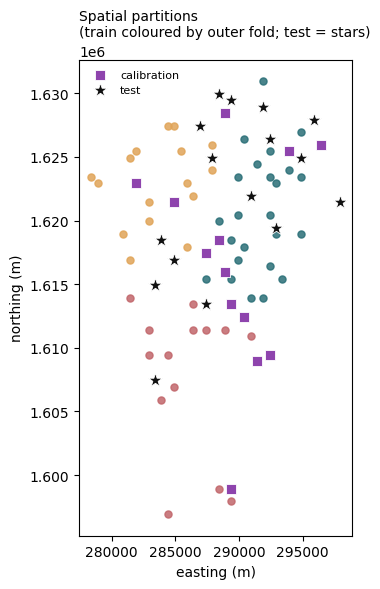

In [6]:
cent = spatial_cv.get_grid_centroids(MAPPING).set_index('Grid_ID')
outer_of = {int(c): int(f) for f, cs in doc['folds']['outer'].items() for c in cs}
palette = ['#2a6f77', '#c1666b', '#e0a458']

fig, ax = plt.subplots(figsize=(6.4, 6.0))
for name, col, mk in [('train', None, 'o'), ('calibration', '#8e44ad', 's'), ('test', '#111111', '*')]:
    cs = parts[name]
    pts = cent.loc[[c for c in cs if c in cent.index]]
    if name == 'train':
        for ci, cc in enumerate(pts.index):
            ax.scatter(pts.loc[cc, 'cx'], pts.loc[cc, 'cy'], s=26,
                       color=palette[outer_of.get(int(cc), 0) % 3], marker='o', alpha=0.85)
    else:
        ax.scatter(pts['cx'], pts['cy'], s=110 if name == 'test' else 60, color=col,
                   marker=mk, edgecolor='white', linewidth=0.6, label=name, zorder=5)
ax.set_aspect('equal'); ax.set_xlabel('easting (m)'); ax.set_ylabel('northing (m)')
ax.set_title('Spatial partitions\n(train coloured by outer fold; test = stars)', fontsize=10, loc='left')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Five-arm ablation

`A` time only · `B` morphology+time · `C` full · `C+` full+spatial lag · `TEXTURE` full+10 m patch
statistics. Nested spatial CV: 3 outer folds, 3 inner folds, Bayesian (GP-EI) hyperparameter search.

In [7]:
ARMS = ['A', 'B', 'C', 'C+', 'TEXTURE']
_p = 'outputs/ablation_results.csv'
HAVE_RESULTS = False
if os.path.exists(_p):
    _r = pd.read_csv(_p)
    _per = _r.groupby('arm').size()
    HAVE_RESULTS = set(ARMS) <= set(_r['arm']) and all(_per.get(a, 0) >= 3 for a in ARMS)
    print('existing folds per arm:', {a: int(_per.get(a, 0)) for a in ARMS})
print('reuse existing results:', HAVE_RESULTS)

existing folds per arm: {'A': 3, 'B': 3, 'C': 3, 'C+': 3, 'TEXTURE': 3}
reuse existing results: True


In [8]:
N_TRIALS = 20          # thesis setting; 3 gives a ~10 min read

if HAVE_RESULTS:
    print('skipping training: all 5 arms x 3 folds already in outputs/ablation_results.csv')
else:
    !python ablation.py --arms A B C C+ TEXTURE --n-trials {N_TRIALS}

skipping training: all 5 arms x 3 folds already in outputs/ablation_results.csv


In [9]:
# arm names are not safe filenames ('C+' -> 'Cplus'), and BEST is used by later cells
summary = pd.read_csv('outputs/ablation_summary.csv').sort_values('pooled_r2', ascending=False)
BEST = summary['arm'].iloc[0]
ARM_FILE = {'A': 'A', 'B': 'B', 'C': 'C', 'C+': 'Cplus', 'TEXTURE': 'TEXTURE'}
print(summary[['arm','label','n_features','pooled_rmse','pooled_mae','pooled_r2',
               'r2_mean','r2_sd','oof_rows']].round(3).to_string(index=False))
print('\nwinning arm:', BEST)


    arm               label  n_features  pooled_rmse  pooled_mae  pooled_r2  r2_mean  r2_sd  oof_rows
      A         A TIME_ONLY          18        9.329       3.953      0.569    0.611  0.105    881981
      C              C FULL          24        9.380       3.962      0.564    0.606  0.110    881981
TEXTURE           D TEXTURE          59        9.532       3.988      0.550    0.592  0.116    881981
     C+ C+ FULL+spatial lag          27        9.743       4.025      0.530    0.574  0.117    881981
      B        B MORPH_TIME          15       14.607       8.623     -0.057   -0.040  0.063    881981

winning arm: A


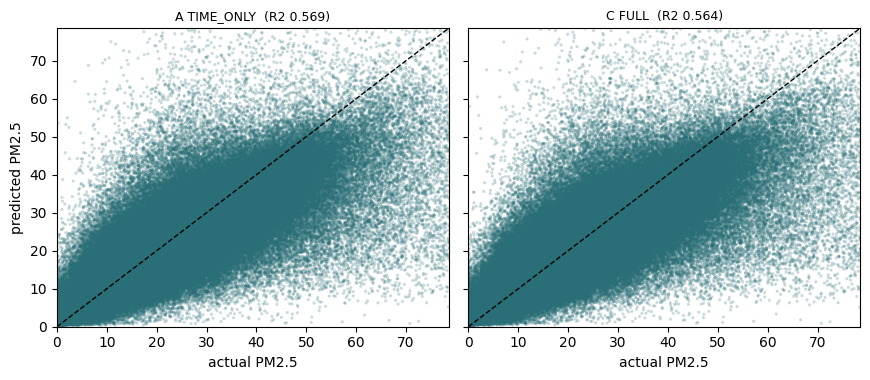

In [10]:
shown = list(dict.fromkeys(['A', 'C', BEST]))      # dedupe if BEST is A or C
oof = {a: pd.read_csv('outputs/oof_predictions_%s.csv' % ARM_FILE[a]) for a in shown}
lims = [0, float(np.nanpercentile(oof[shown[0]]['actual'], 99.5))]

fig, axes = plt.subplots(1, len(shown), figsize=(4.4 * len(shown), 3.9), sharex=True, sharey=True,
                         squeeze=False)
for ax, a in zip(axes.ravel(), shown):
    d = oof[a]
    ax.scatter(d['actual'], d['predicted'], s=5, alpha=0.25, color='#2a6f77', edgecolors='none')
    ax.plot(lims, lims, 'k--', lw=1)
    r2 = summary.set_index('arm').loc[a, 'pooled_r2']
    ax.set_title('%s  (R2 %.3f)' % (ARM_LABELS[a], r2), fontsize=9)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('actual PM2.5')
axes.ravel()[0].set_ylabel('predicted PM2.5')
plt.tight_layout(); plt.show()


## 5. The reserved test stations

Never used for training, tuning or calibration. This is the headline accuracy.

In [11]:
!python run_pipeline.py --stage test --test-arm {BEST}
print(pd.read_csv('outputs/test_metrics_all.csv')[['arm','stations','rmse','mae','r2','ia',
                                                   'pearson_r','bias','within_5','within_10']]
      .round(3).to_string(index=False))

stage: test
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
arm A: fitting on 54 training cells (881,981 rows), scoring 16 test cells (325,070 rows)
  hyperparameters: {'colsample_bytree': 0.798, 'gamma': 0.5, 'learning_rate': 0.046, 'max_depth': 4, 'min_child_weight': 4, 'reg_alpha': 3.337, 'reg_lambda': 0.829, 'subsample': 0.89}, n_estimators=383  [ablation best fold]

=== TEST partition (stations the model never saw) ===
  metric                        value


## 6. Spatial bias in the out-of-fold residuals (Section 4.4.3)

If errors cluster geographically, a purely aspatial model is missing something the map could supply.
Moran's I on the per-cell mean residual answers that directly.

In [12]:
from preprocessing.spatial_bias import (aggregate_residuals_by_grid, build_knn_weights,
                                        global_morans_i, local_morans_i)

oof_df = pd.read_csv(f'outputs/oof_predictions_{ARM_FILE[BEST]}.csv')
grid_res = aggregate_residuals_by_grid(oof_df, MAPPING)
print('aggregated to %d grid cells' % len(grid_res))

w = build_knn_weights(grid_res, k=4)
I, p_value = global_morans_i(grid_res['residual'].values, w)
print("Global Moran's I: %+.3f   (p = %.3f, %d cells)" % (I, p_value, len(grid_res)))

if p_value < 0.05:
    lisa = pd.concat([grid_res[['Grid_ID','residual']].reset_index(drop=True),
                      local_morans_i(grid_res['residual'].values, w)], axis=1)
    print(lisa.sort_values('p_sim').head(10).to_string(index=False))
else:
    print('-> no statistically significant spatial clustering of residuals at this alpha')

aggregated to 54 grid cells
Global Moran's I: +0.101   (p = 0.246, 54 cells)
-> no statistically significant spatial clustering of residuals at this alpha


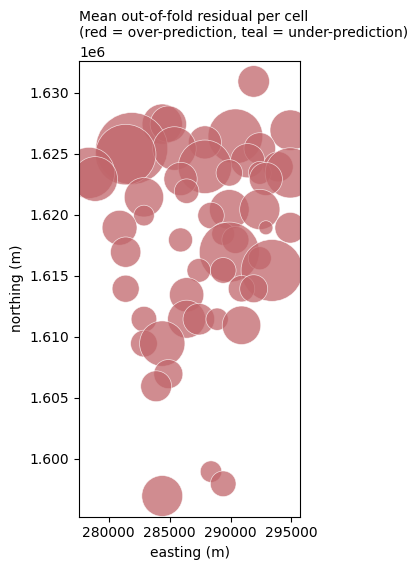

In [13]:
fig, ax = plt.subplots(figsize=(6.2, 5.8))
sizes = 80 + 2600 * (grid_res['residual'].abs() / grid_res['residual'].abs().max())
colors = np.where(grid_res['residual'] >= 0, '#c1666b', '#2a6f77')
ax.scatter(grid_res['cx'], grid_res['cy'], s=sizes, c=colors, alpha=0.75, edgecolor='white',
           linewidth=0.5)
ax.set_aspect('equal')
ax.set_title('Mean out-of-fold residual per cell\n(red = over-prediction, teal = under-prediction)',
             fontsize=10, loc='left')
ax.set_xlabel('easting (m)'); ax.set_ylabel('northing (m)')
plt.tight_layout(); plt.show()

## 7. Prediction intervals — GeoCP, matched to the CNN-LSTM settings

Kernel × bandwidth grid `[2000, 5000, 10000, 20000, inf]` with gaussian and exponential kernels, selected
by leave-one-station-out on the calibration stations, `finite_sample_correction = False`.

In [14]:
!python run_pipeline.py --stage geocp --geocp-profile shared --max-cal 6000 --max-eval 20000

stage: geocp
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
test rows subsampled for evaluation: 20,000 of 325,070 (seed 42)
calibration records subsampled: 6,000 of 271,962 (seed 42)

=== leave-one-calibration-station-out over kernels x bandwidths ===
  gaussian     done
  exponential  done

selected: kernel=gaussian  h=2000.0
  LOSO mean coverage 0.8967 | WORST fold 0.7764 | mean width 16.269
  rule: worst fold must be >= 0.88 (target 0.90 - tolerance 0.02) -

In [15]:
import json
g = json.load(open('outputs/geocp_shared/geocp.json'))
print('selected kernel :', g['selected']['kernel'], '@', g['selected']['bandwidth_m'], 'm')
print('LOSO coverage   : %.3f' % g['selected']['loso_coverage'])
print('TEST coverage   : %.4f  (target %.2f)' % (g['test']['coverage'], g['test']['target_coverage']))
print('mean width      : %.2f ug/m3' % g['test']['mean_width'])
cand = pd.read_csv('outputs/geocp_shared/geocp_candidates.csv')
display(cand.round(3).sort_values('loso_coverage', ascending=False).head(8))


selected kernel : gaussian @ 2000.0 m
LOSO coverage   : 0.897
TEST coverage   : 0.8956  (target 0.90)
mean width      : 14.86 ug/m3


,kernel,bandwidth_m,loso_coverage,loso_worst_fold_coverage,loso_mean_width
0,gaussian,2000.0,0.897,0.776,16.269
1,exponential,2000.0,0.891,0.732,15.634
8,gaussian,NaN,0.890,0.720,15.489
9,exponential,NaN,0.890,0.720,15.489
7,gaussian,20000.0,0.890,0.720,15.468
6,exponential,20000.0,0.889,0.720,15.431
4,exponential,10000.0,0.888,0.720,15.318
5,gaussian,10000.0,0.888,0.720,15.325


## 8. The model artifact

In [16]:
!python run_pipeline.py --stage save
print(open('outputs/artifacts/latest/features.json', encoding='utf-8').read()[:400])

stage: save
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
  deploying arm A, 18 features, fold 1's hyperparameters, n_estimators=383
  fitted on 881,981 rows from 54 training cells
  artifact written to C:\Users\delac\Downloads\thesis_model\XGBoost\outputs\artifacts\latest
done
{
  "features": [
    "hour_sin",
    "hour_cos",
    "dayofweek_sin",
    "dayofweek_cos",
    "month_sin",
    "month_cos",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_3",
    "

## 9. Interpretability — gain importance and TreeSHAP

Grad-CAM does not apply to a tree ensemble (there is no convolutional feature map to attribute), so
attribution uses TreeSHAP, which is exact and additive for tree models.

In [17]:
import joblib
model = joblib.load('outputs/artifacts/latest/model.joblib')
gain = pd.Series(model.get_booster().get_score(importance_type='gain'))
gain.index = [int(i[1:]) for i in gain.index]          # 'f0' -> 0
gain = gain.reindex(range(len(ARM_FEATURES[BEST]))).fillna(0)
gain.index = ARM_FEATURES[BEST]
gain = (gain / gain.sum()).sort_values()
print(gain.tail(10).round(3).to_string())


pm25_roll72_mean    0.004
hour_x_bldg_dens    0.006
pm25_roll72_std     0.006
hour_cos            0.007
hour_sin            0.016
pm25_diff_1_2       0.029
pm25_roll24_mean    0.054
pm25_lag_2          0.067
pm25_lag_3          0.122
pm25_lag_1          0.670


gain share of the 6 morphological features: 0.0%


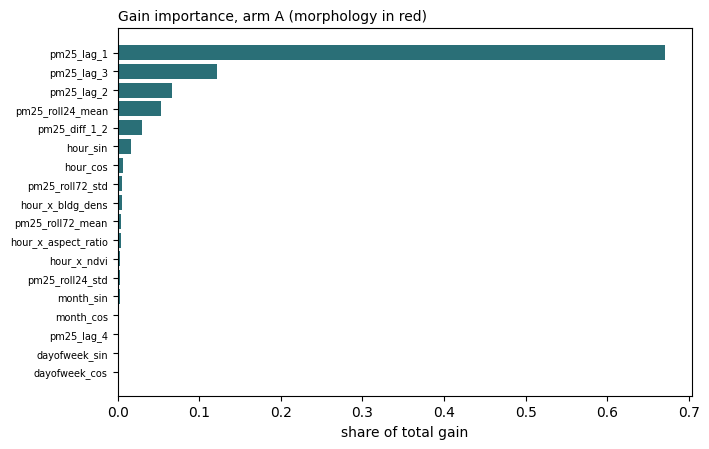

In [18]:
morph_cols = ['bh_mean','bh_stdev','ndvi_mean','bldg_dens','aspect_ratio_mean','street_width_mean']
present = [c for c in morph_cols if c in gain.index]
morph_share = 100.0 * gain[present].sum() if present else 0.0
print('gain share of the 6 morphological features: %.1f%%' % morph_share)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
colors = ['#c0392b' if f in morph_cols else '#2a6f77' for f in gain.index]
ax.barh(range(len(gain)), gain.values, color=colors)
ax.set_yticks(range(len(gain))); ax.set_yticklabels(gain.index, fontsize=7)
ax.set_xlabel('share of total gain')
ax.set_title('Gain importance, arm %s (morphology in red)' % BEST, fontsize=10, loc='left')
plt.tight_layout(); plt.show()


In [19]:
!python run_pipeline.py --stage figures --figures-arm {BEST}

stage: figures
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
=== figures -> C:\Users\delac\Downloads\thesis_model\XGBoost\outputs\figures ===
  using predictions_test_A.csv
  pred_vs_obs.png              ok
  residual_hist.png            ok
  accuracy_by_station.png      ok
  timeseries_sample.png        ok
  error_vs_concentration.png   ok
  geocp_coverage.png           source: geocp_shared
  geocp_coverage.png           ok
Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
  shap_importance.png          ok
 

shap_beeswarm.png


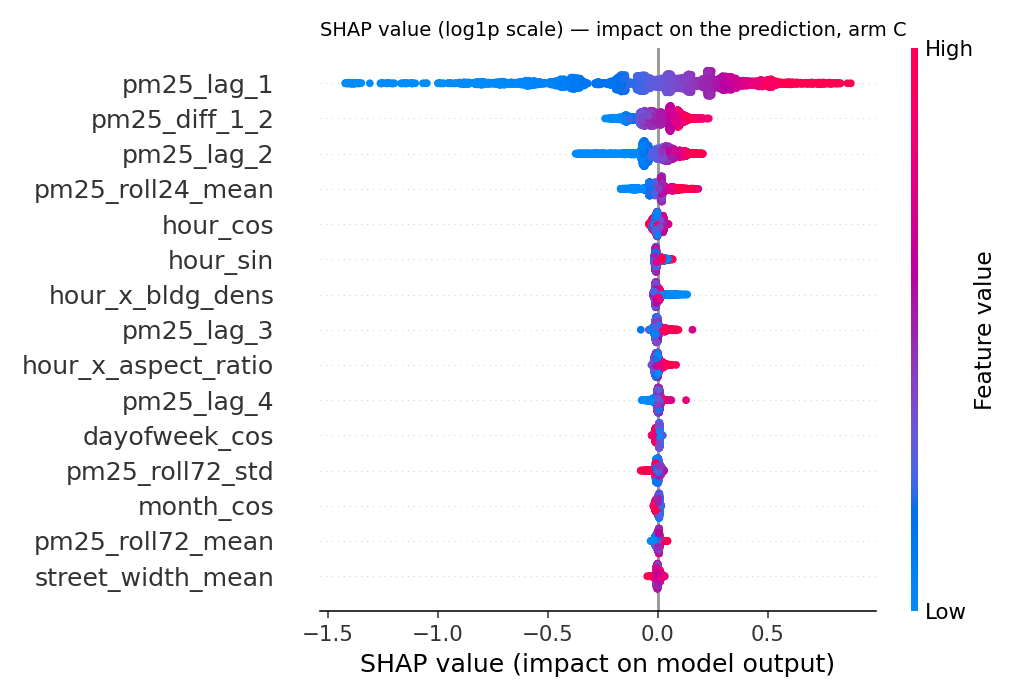

shap_waterfall.png


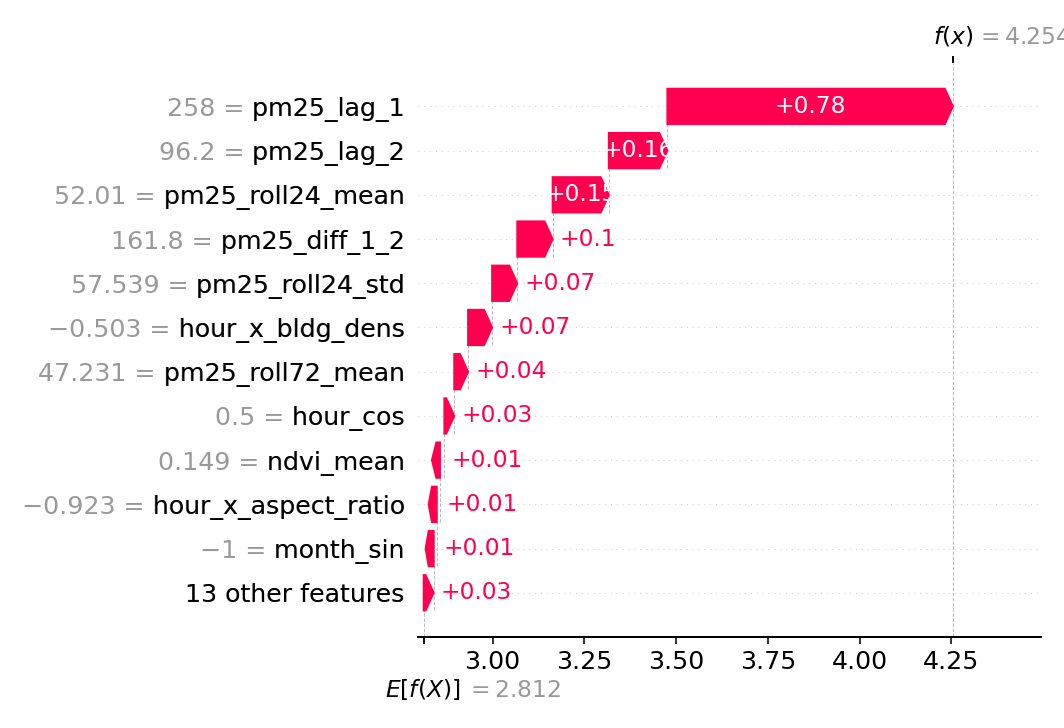

shap_importance.png


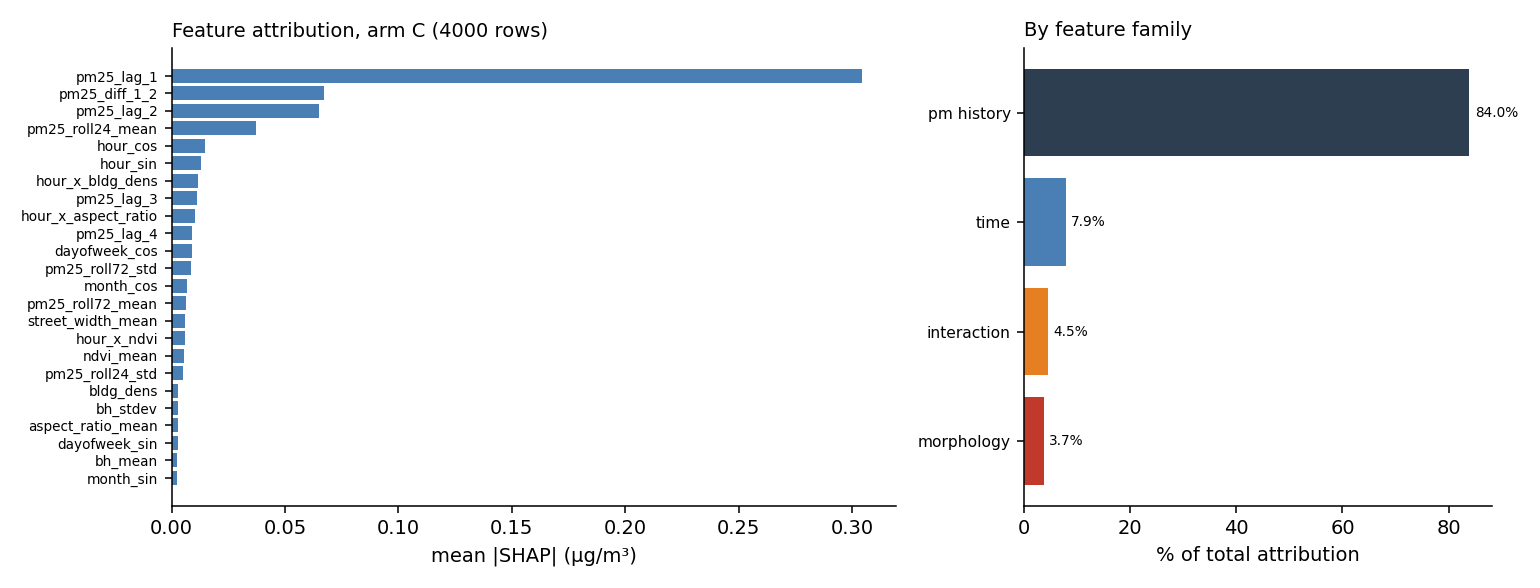

pred_vs_obs.png


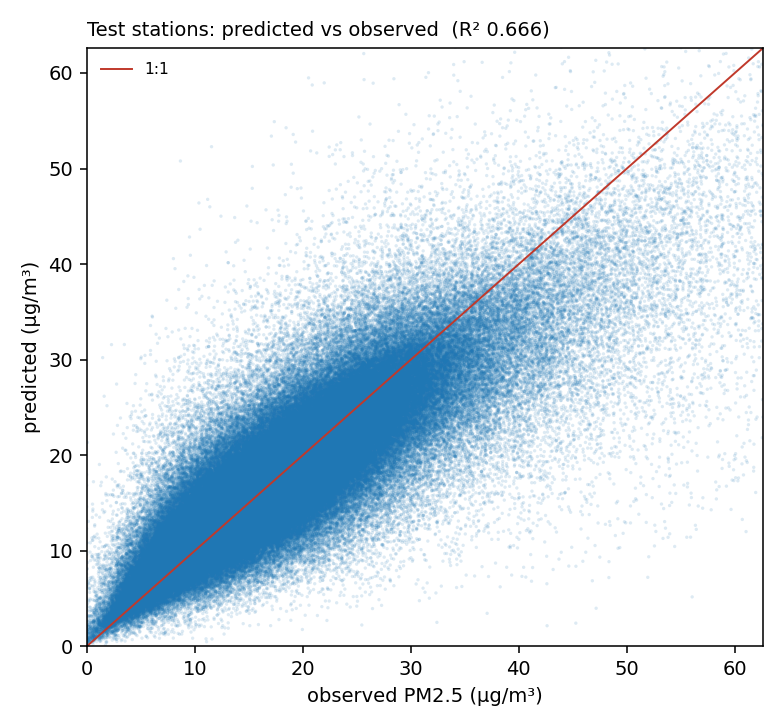

error_vs_concentration.png


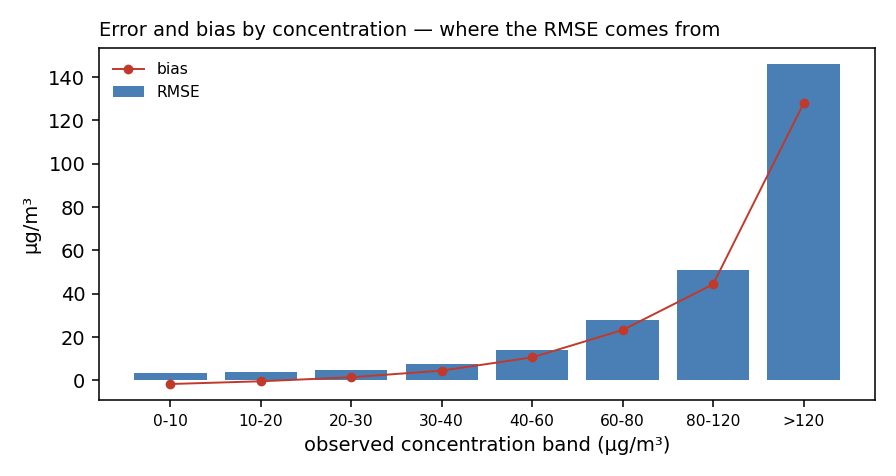

accuracy_by_station.png


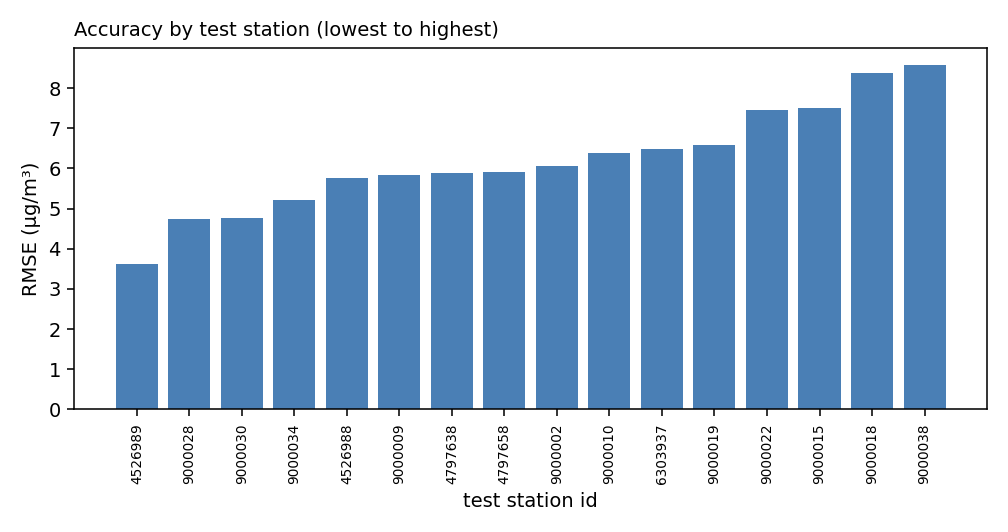

residual_hist.png


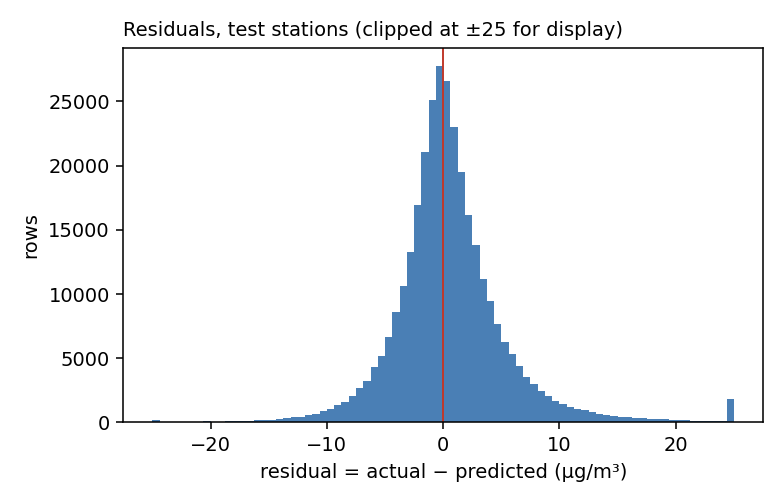

timeseries_sample.png


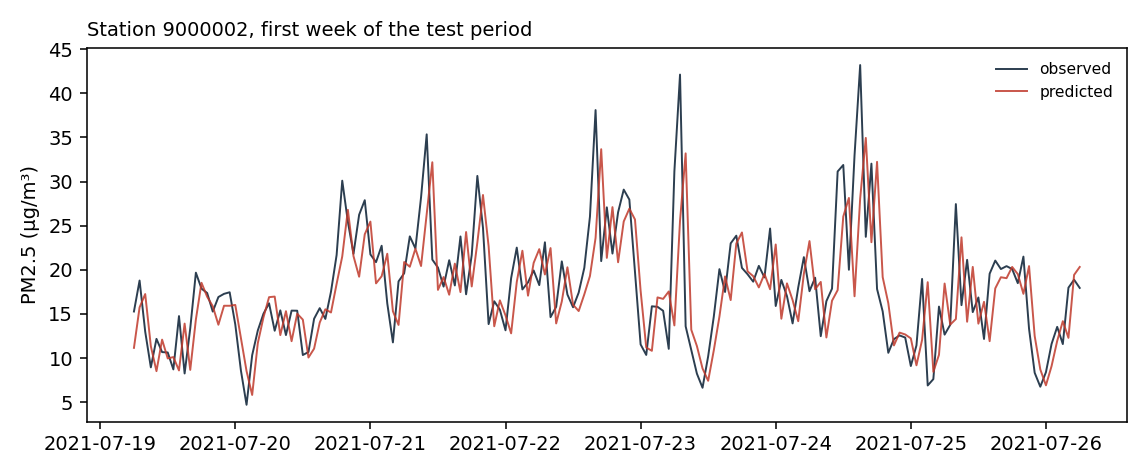

geocp_coverage.png


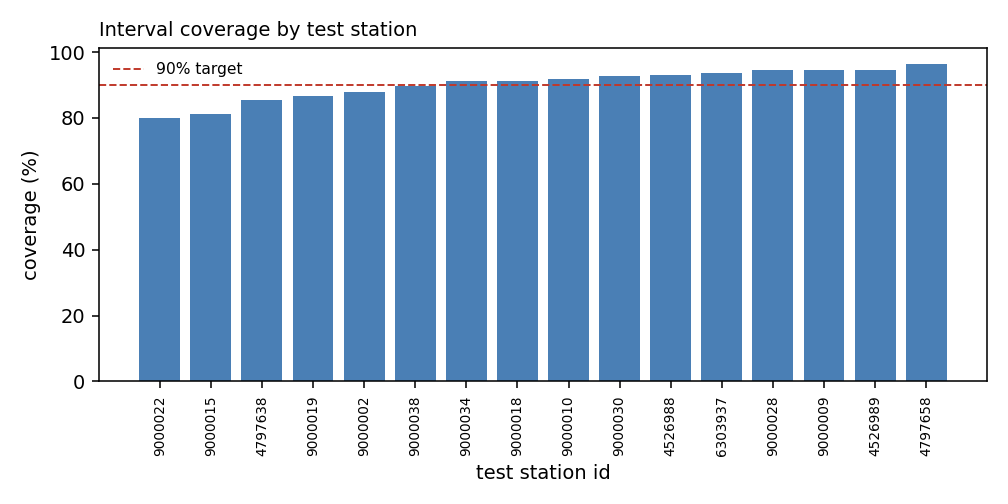

In [20]:
from IPython.display import Image, display
for f in ['shap_beeswarm.png','shap_waterfall.png','shap_importance.png','pred_vs_obs.png',
          'error_vs_concentration.png','accuracy_by_station.png','residual_hist.png',
          'timeseries_sample.png','geocp_coverage.png']:
    p = os.path.join('outputs/figures', f)
    if os.path.exists(p):
        print(f); display(Image(p, width=640))

## 10. City-wide surfaces — continuous gradient

Four snapshots on one shared colour scale, plus a 24-hour mean. No AQI tiers: this pipeline's
predictions cluster in a narrow band, which put almost every cell in the same AQI bin and made the tiered
map a flat colour.

In [21]:
DATE = '2025-07-23'
!python run_pipeline.py --stage infer --date {DATE}

stage: infer
  dataset=full  folds=fold_partitions_shared.json  master=Master_DL_Ready_full.csv  grid=morphology_grid_full.csv
Loading data...
Wrote C:\Users\delac\Downloads\thesis_model\XGBoost\data\sensor_to_grid_map_full.csv: 84 sensors -> 83 unique grid cells (84 rows, 18 columns)
Merging morphology metrics...
Engineering temporal features...
Computing time-aware lags & rolling stats (this replaces Master_DL_Ready.csv's own pm25_t-1/t-2/t-3, which are naive row-shifts -- see module docstring)...
Preparing model training...
Final matrix: X=(1479013, 24), y=(1479013,), unique groups=83
  deploying arm A, 18 features, fold 1's hyperparameters, n_estimators=383
  fitted on 881,981 rows from 54 training cells
  2025-07-23 08:00:00: 3687/3696 cells usable, mean stand-in coverage 1.00
    table -> outputs\surfaces\20250723\20250723T0800.csv (3696 rows)
    raster -> outputs\surfaces\20250723\20250723T0800.tif (77x48, 4 bands, LZW)
    map -> outputs\surfaces\20250723\20250723T0800_aqi.png

panel_20250723.png


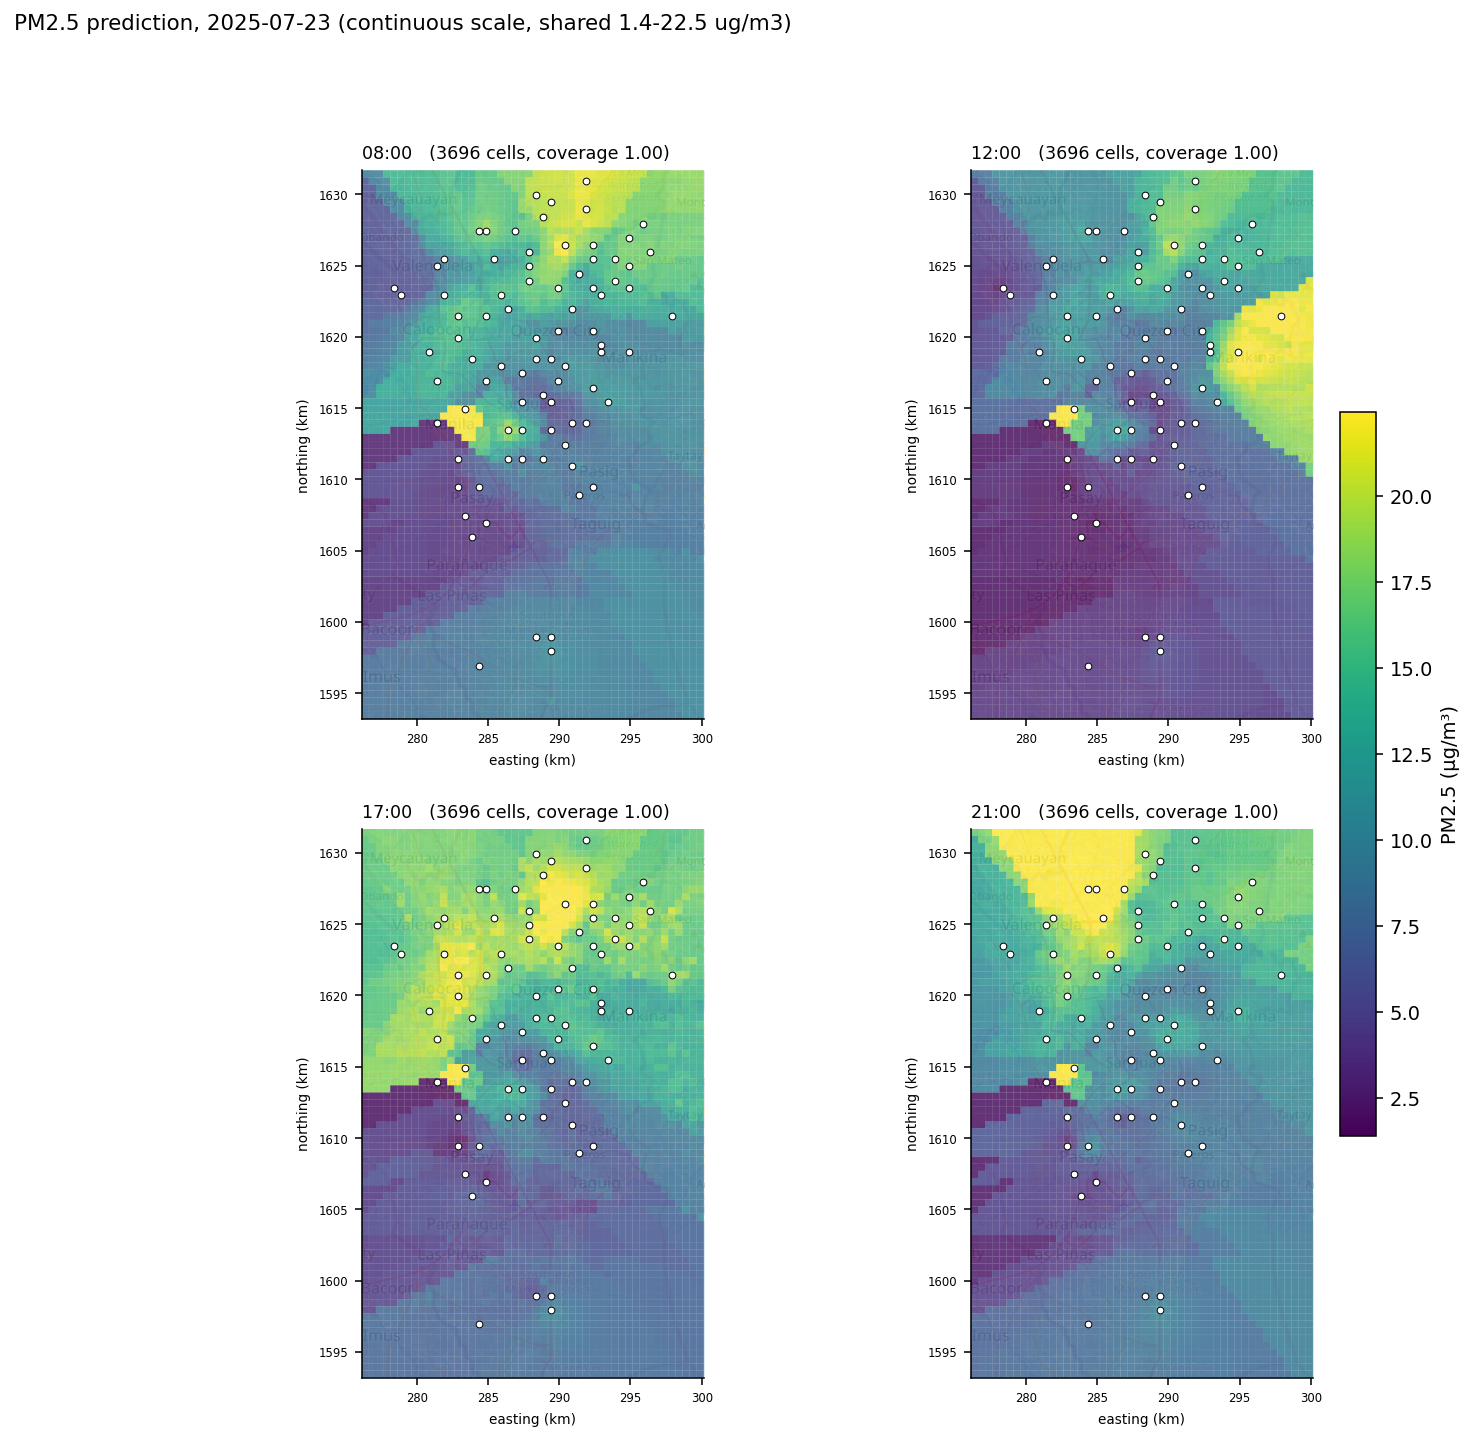

20250723_mean_continuous.png


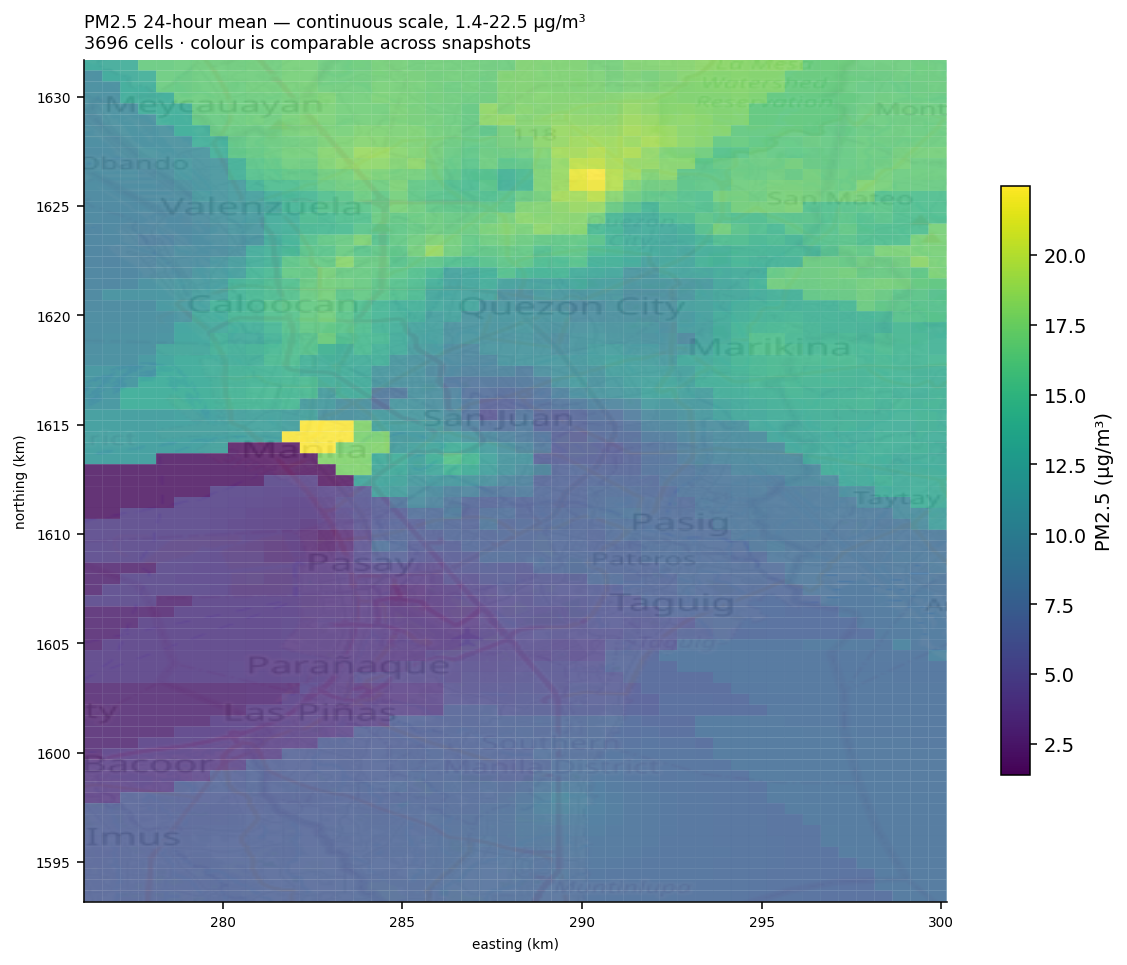

In [22]:
day = DATE.replace('-', '')
out = os.path.join('outputs/surfaces', day)
for name in [f'panel_{day}.png', f'{day}_mean_continuous.png']:
    p = os.path.join(out, name)
    if os.path.exists(p):
        print(name); display(Image(p, width=780))

## 11. Summary

In [23]:
print('network      :', df_clean['Grid_ID'].nunique(), 'cells /', df_clean['Location'].nunique(),
      'stations,', f'{len(df_clean):,}', 'rows')
print('winning arm  :', BEST, '(%d features)' % len(ARM_FEATURES[BEST]))
t = pd.read_csv('outputs/test_metrics_all.csv').set_index('arm').loc[BEST]
print('test stations: R² %.3f | MAE %.3f | RMSE %.3f | bias %+.3f'
      % (t['r2'], t['mae'], t['rmse'], t['bias']))
print('intervals    : coverage %.3f (target %.2f), width %.1f µg/m³'
      % (g['test']['coverage'], g['test']['target_coverage'], g['test']['mean_width']))
print('morphology   : %.1f%% of gain, %.1f%% of SHAP attribution'
      % (morph_share, json.load(open('outputs/figures/shap_importance.json'))['families_pct']
         .get('morphology', 0.0)))

network      : 83 cells / 84 stations, 1,479,013 rows
winning arm  : A (18 features)
test stations: R² 0.666 | MAE 3.503 | RMSE 6.493 | bias +0.669
intervals    : coverage 0.896 (target 0.90), width 14.9 µg/m³
morphology   : 0.0% of gain, 3.7% of SHAP attribution
